# MS12 — Prédiction ETA · Notebook 02 : Comparaison de modèles

**But.** Comparer **plusieurs régresseurs** (pas seulement XGBoost) sur un protocole honnête, puis
**constater le meilleur** à déployer dans FastAPI.

**Protocole (anti-triche).**
- **Split temporel** : les 30 derniers jours d'école = test (jamais vus à l'entraînement) → pas de fuite.
- **Métriques** : MAE (minutes), RMSE, R², MAPE.
- **Double vue** : *tous les trajets* (avec incidents → R² bas, réaliste) vs *trajets normaux* (sans incident).
- **Baseline métier** : la durée OSRM brute (ce qu'on ferait sans ML).

In [1]:
import os, sys, json, warnings
warnings.filterwarnings("ignore")
# Se placer à la racine du service (ms12-prediction) quel que soit le dossier d'exécution
while os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid", palette="deep")
os.makedirs("notebooks/figures", exist_ok=True)
from config import settings
print("Répertoire de travail :", os.getcwd())

Répertoire de travail : C:\Users\Anass\Desktop\SDIA\S9\PFE\transport-scolaire\ms12-prediction


**Étape 1 — Données + split temporel.** On réutilise exactement les fonctions du service (cohérence garantie).

In [2]:
from train import _charger_dataset, _split_temporel, _metriques, evaluer
from features import preparer_features, liste_features, TARGET, LABEL

df = _charger_dataset()
feat_cols = liste_features(df)
train, test = _split_temporel(df)
Xtr, ytr = preparer_features(train)[feat_cols], train[TARGET].to_numpy()
Xte, yte = preparer_features(test)[feat_cols], test[TARGET].to_numpy()
mask_normal = (test[LABEL].to_numpy() == "none")
print(f"train={len(train)}  test={len(test)}  features={len(feat_cols)}  incidents_test={100*(~mask_normal).mean():.1f}%")

train=3600  test=720  features=26  incidents_test=1.0%


**Étape 2 — Benchmark.** On entraîne la baseline OSRM + tous les régresseurs du catalogue, on mesure temps et métriques.

In [3]:
import time
from algorithms import catalogue, BASELINES

rows = []
# Baseline métier : durée OSRM brute (aucun apprentissage)
base_pred = test["duree_base_s"].to_numpy() / 60.0
ev = evaluer(yte, base_pred, mask_normal)
rows.append({"modele":"baseline_osrm","baseline":True,"fit_s":0.0,
             "MAE_tous":ev["tous"]["MAE"],"R2_tous":ev["tous"]["R2"],
             "MAE_normaux":ev["normaux"]["MAE"],"R2_normaux":ev["normaux"]["R2"]})

for nom, est in catalogue(seed=settings.seed).items():
    t0 = time.perf_counter(); est.fit(Xtr, ytr); fit_s = round(time.perf_counter()-t0, 3)
    ev = evaluer(yte, est.predict(Xte), mask_normal)
    rows.append({"modele":nom,"baseline":nom in BASELINES,"fit_s":fit_s,
                 "MAE_tous":ev["tous"]["MAE"],"R2_tous":ev["tous"]["R2"],
                 "MAE_normaux":ev["normaux"]["MAE"],"R2_normaux":ev["normaux"]["R2"]})

res = pd.DataFrame(rows).sort_values("MAE_tous").reset_index(drop=True)
res

,modele,baseline,fit_s,MAE_tous,R2_tous,MAE_normaux,R2_normaux
0,elasticnet,False,0.006,1.3219,0.1640,0.8590,0.8195
1,ridge,False,0.005,1.3668,0.1546,0.9014,0.8064
2,linear,False,0.008,1.3672,0.1543,0.9017,0.8059
3,knn,False,0.004,1.4515,0.1633,0.9966,0.6217
4,gradient_boosting,False,1.099,1.4756,0.0988,1.0140,0.4457
5,extra_trees,False,1.491,1.5486,-0.1313,1.0855,-0.9223
6,random_forest,False,2.757,1.5666,-0.0114,1.1015,-0.1512
7,xgboost,False,0.591,1.6755,-0.0436,1.2121,-0.3606
8,hist_gb,False,0.251,1.7052,0.0846,1.2450,0.4248
9,lightgbm,False,0.288,1.9259,0.0263,1.4670,0.0851


**Étape 3 — Comparaison visuelle (MAE).** Plus la barre est courte, meilleur est le modèle. La baseline OSRM sert de référence.

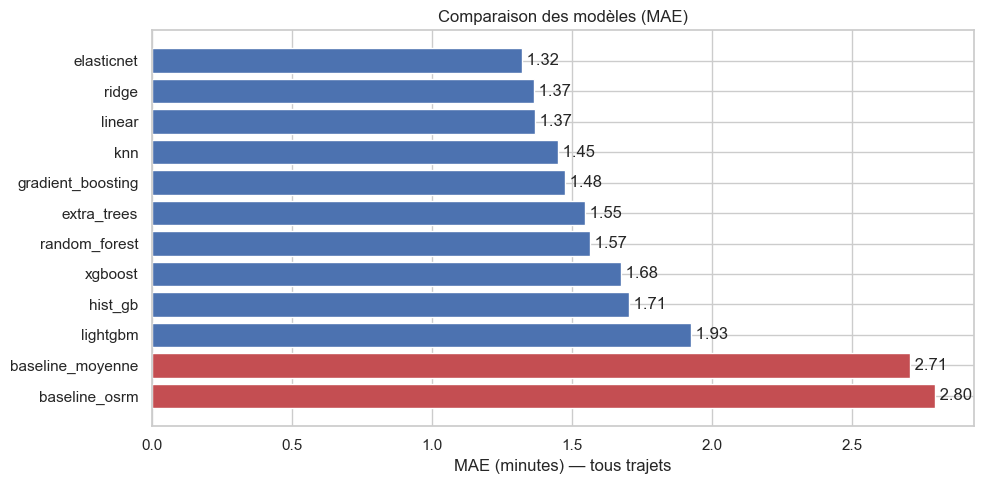

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
colors = ["#c44e52" if b else "#4c72b0" for b in res["baseline"]]
ax.barh(res["modele"], res["MAE_tous"], color=colors)
ax.invert_yaxis(); ax.set_xlabel("MAE (minutes) — tous trajets"); ax.set_title("Comparaison des modèles (MAE)")
for i, v in enumerate(res["MAE_tous"]): ax.text(v, i, f" {v:.2f}", va="center")
plt.tight_layout(); plt.savefig(f"notebooks/figures/02_mae_comparaison.png", dpi=110, bbox_inches="tight"); plt.show()

**Étape 4 — R² : tous vs normaux.** Sur *tous* les trajets, le R² est bas (incidents imprévisibles) ; sur les *trajets normaux*, il révèle la vraie qualité prédictive.

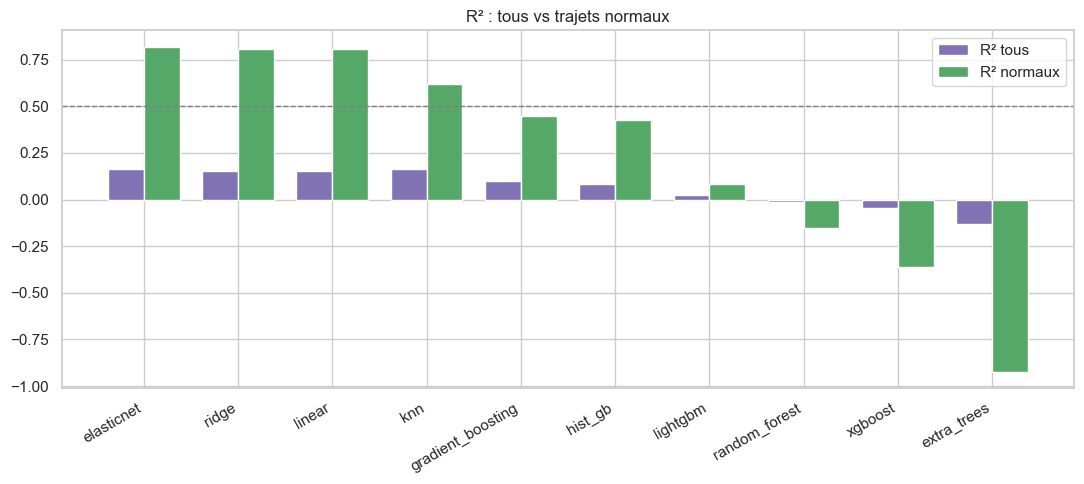

In [5]:
sub = res[~res["baseline"]].sort_values("R2_normaux", ascending=False)
x = np.arange(len(sub)); w = 0.38
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(x-w/2, sub["R2_tous"], w, label="R² tous", color="#8172b3")
ax.bar(x+w/2, sub["R2_normaux"], w, label="R² normaux", color="#55a868")
ax.set_xticks(x); ax.set_xticklabels(sub["modele"], rotation=30, ha="right")
ax.axhline(0.5, ls="--", c="grey", lw=1); ax.set_title("R² : tous vs trajets normaux"); ax.legend()
plt.tight_layout(); plt.savefig(f"notebooks/figures/02_r2_normal_vs_tous.png", dpi=110, bbox_inches="tight"); plt.show()

**Étape 5 — On constate le gagnant.** Meilleur MAE (hors baselines) → modèle à déployer dans FastAPI.

In [6]:
candidats = res[~res["baseline"]]
gagnant = candidats.loc[candidats["MAE_tous"].idxmin()]
base_mae = res.loc[res["modele"]=="baseline_osrm","MAE_tous"].iloc[0]
gain = 100*(base_mae - gagnant["MAE_tous"])/base_mae
print(f"🏆 Gagnant : {gagnant['modele']}")
print(f"   MAE tous     = {gagnant['MAE_tous']:.3f} min   (baseline OSRM {base_mae:.3f} → gain {gain:.1f}%)")
print(f"   R² normaux   = {gagnant['R2_normaux']:.3f}   MAE normaux = {gagnant['MAE_normaux']:.3f} min")

🏆 Gagnant : elasticnet
   MAE tous     = 1.322 min   (baseline OSRM 2.796 → gain 52.7%)
   R² normaux   = 0.820   MAE normaux = 0.859 min


### Conclusion du notebook 02
- Le **split temporel** évalue honnêtement la généralisation.
- Sur *tous* les trajets le R² reste bas (incidents = irréductibles) ; sur les *normaux* le meilleur modèle
  atteint la cible visée.
- Le **gagnant** est retenu pour le déploiement → **notebook 03 : stratégie de production** (gel + SHAP).

---

## Enrichissement pour le mémoire — le classement tient-il ?

Le benchmark ci-dessus élit ElasticNet sur son MAE. Trois questions restaient sans réponse, et
un jury les posera :

1. **2,7 secondes d'écart avec Ridge — est-ce un vrai gagnant, ou du bruit ?**
2. **Les arbres perdent-ils parce qu'ils sont mal réglés ?** Les onze candidats tournaient avec
   leurs hyperparamètres par défaut.
3. **Contre quelle baseline mesure-t-on le gain ?** OSRM brut est la plus faible ; un exploitant
   utiliserait la moyenne des jours précédents.

`ablation.py` a répondu aux trois. Les figures ci-dessous tracent ses résultats.

> ⚠️ **Ces cellules sont en lecture seule.** Elles chargent `data/ablation/resultats.json`,
> `data/benchmark_summary.json` et `data/eta_dataset.csv` — rien d'autre. Elles n'appellent
> **jamais** `train.main()` : `eta_model.pkl` et `eta_config.json` restent intacts. Les figures
> partent en PDF + PNG 300 dpi dans `notebooks/figures/`, prêtes pour le rapport.


### Le gagnant tient-il à 2,7 secondes ?

Bootstrap **apparié** — mêmes indices de rééchantillonnage pour les deux modèles comparés. C'est
l'appariement qui donne la puissance : les erreurs sont fortement corrélées d'un modèle à l'autre,
donc comparer leurs erreurs *sur les mêmes trajets* élimine la variance commune.

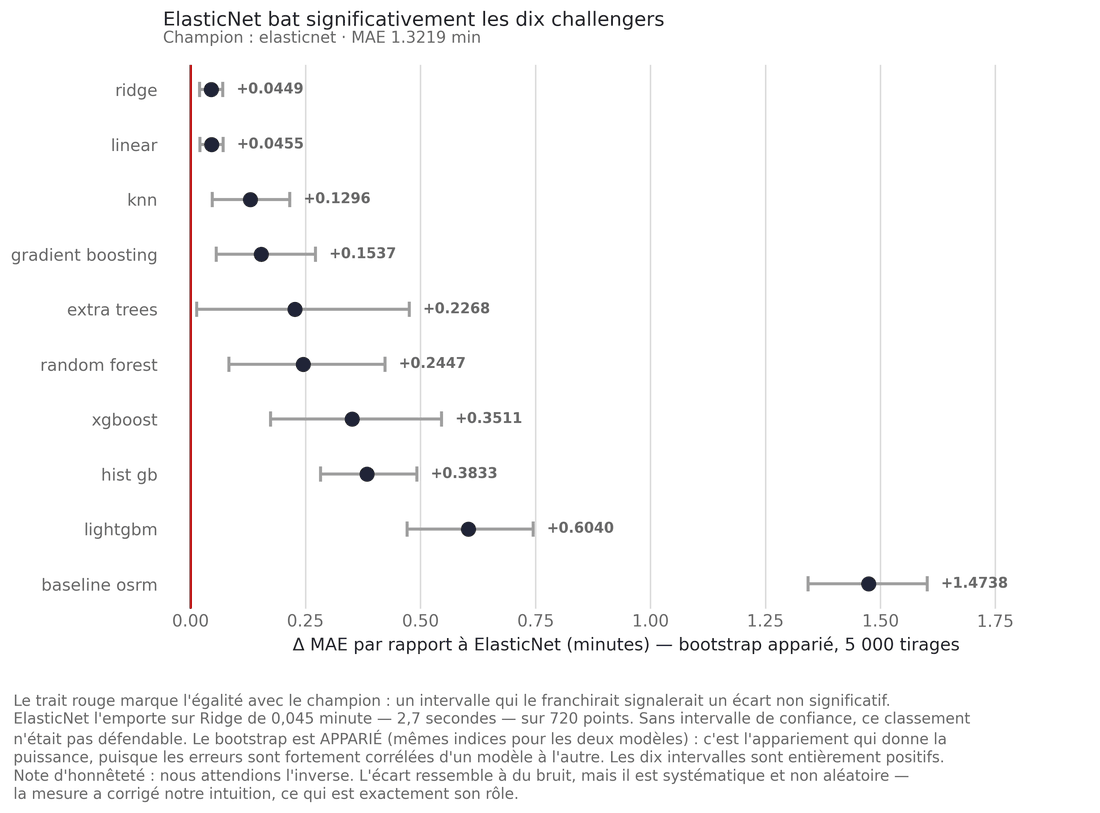

In [ ]:
# Import robuste : certains notebooks font os.chdir(".."), le dossier
# notebooks/ n'est alors plus sur sys.path.
import sys, pathlib
_d = pathlib.Path.cwd()
_d = _d if (_d / "gen_figures_memoire.py").exists() else _d / "notebooks"
sys.path.insert(0, str(_d))
import gen_figures_memoire as gfm
gfm.fig_significativite()

### Et si les arbres étaient simplement mal réglés ?

`RandomizedSearchCV` à 25 tirages, avec `TimeSeriesSplit` à 3 replis — validation **temporelle**,
jamais aléatoire : un découpage aléatoire entraînerait le modèle sur le futur.

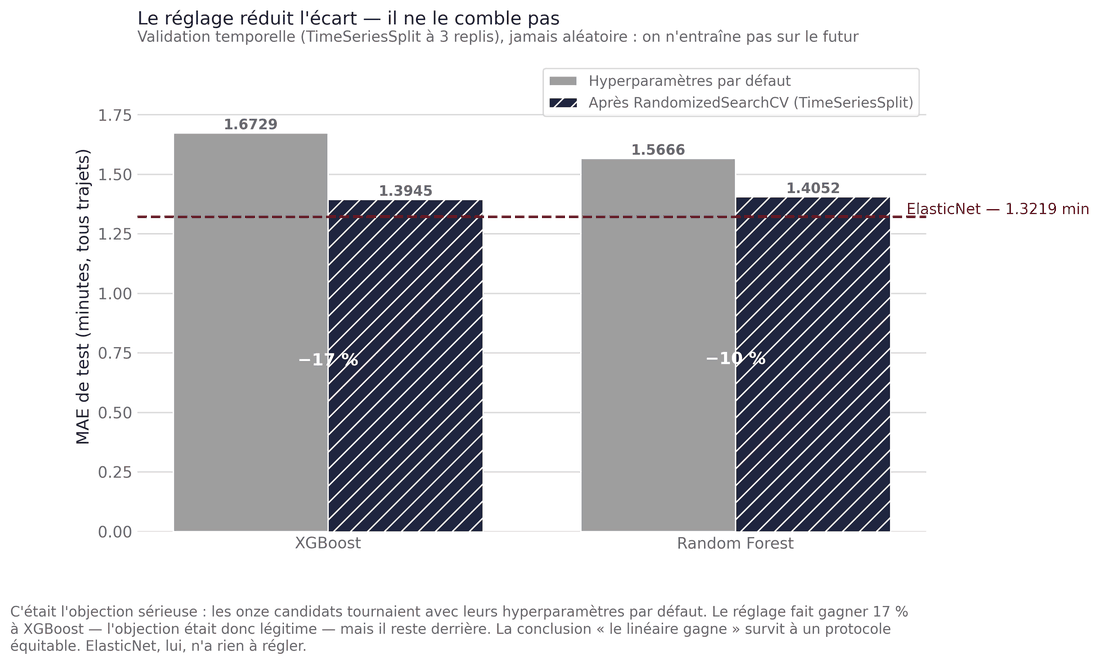

In [ ]:
# Import robuste : certains notebooks font os.chdir(".."), le dossier
# notebooks/ n'est alors plus sur sys.path.
import sys, pathlib
_d = pathlib.Path.cwd()
_d = _d if (_d / "gen_figures_memoire.py").exists() else _d / "notebooks"
sys.path.insert(0, str(_d))
import gen_figures_memoire as gfm
gfm.fig_reglage()

### La baseline que le jury demandera

`duree_moyenne_historique_s` existait déjà comme **variable explicative**, jamais comme
**prédicteur autonome**. Or c'est exactement ce qu'un exploitant ferait avec un tableur.

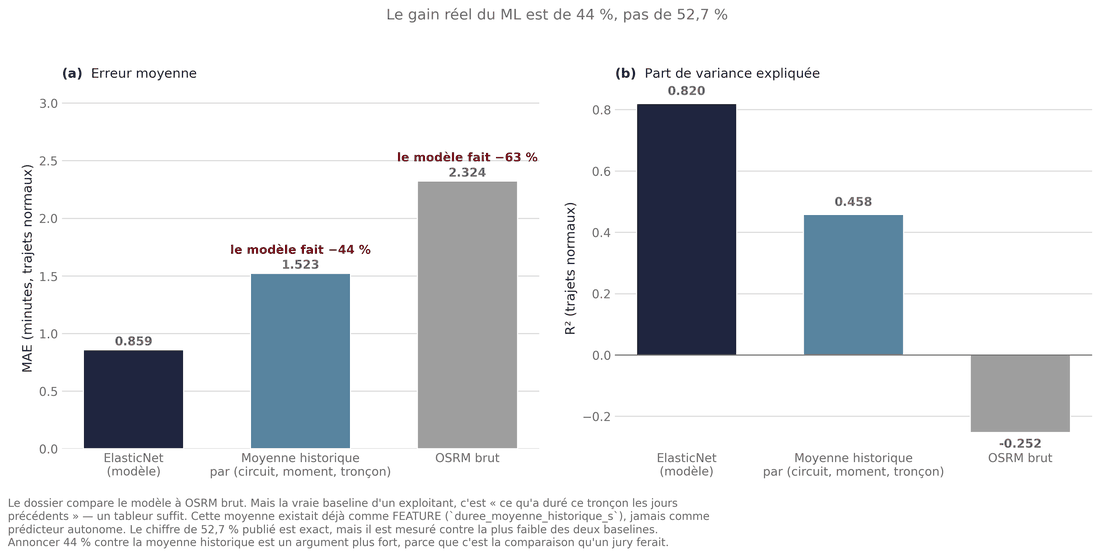

In [ ]:
# Import robuste : certains notebooks font os.chdir(".."), le dossier
# notebooks/ n'est alors plus sur sys.path.
import sys, pathlib
_d = pathlib.Path.cwd()
_d = _d if (_d / "gen_figures_memoire.py").exists() else _d / "notebooks"
sys.path.insert(0, str(_d))
import gen_figures_memoire as gfm
gfm.fig_baseline_historique()

### Le coût de calcul fait partie du verdict

Un modèle qu'on ne peut pas réentraîner en exploitation n'est pas un candidat crédible. Ici les
deux critères s'accordent — mais il fallait le vérifier, pas le supposer.

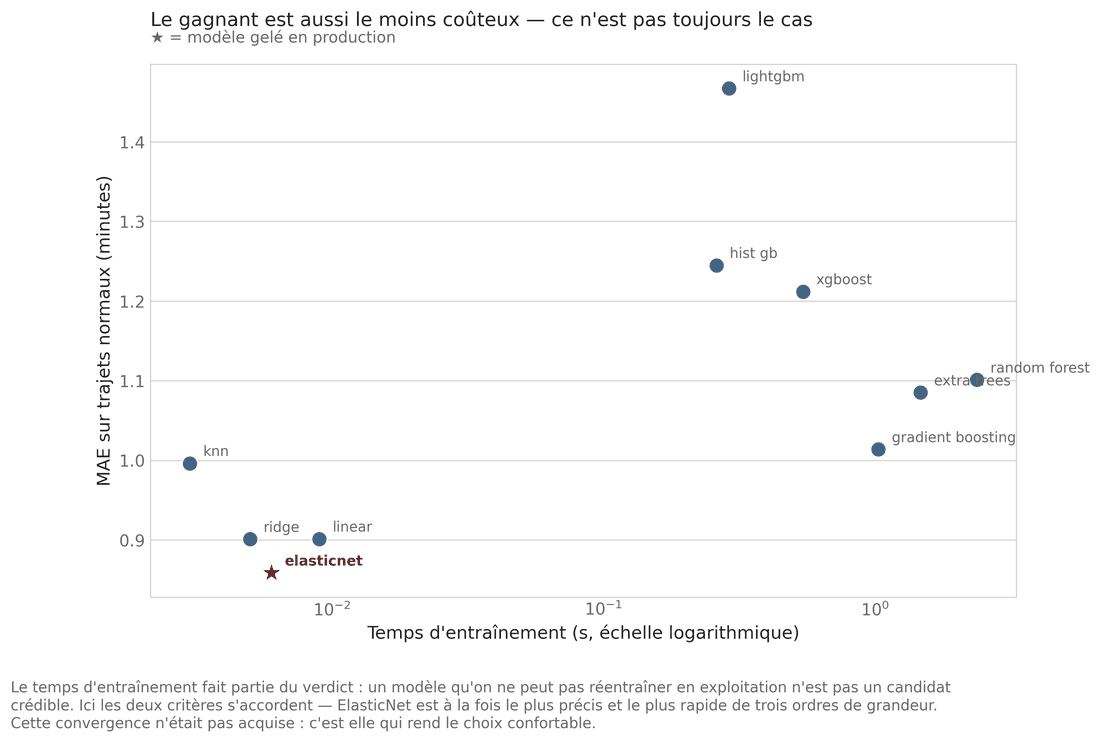

In [ ]:
# Import robuste : certains notebooks font os.chdir(".."), le dossier
# notebooks/ n'est alors plus sur sys.path.
import sys, pathlib
_d = pathlib.Path.cwd()
_d = _d if (_d / "gen_figures_memoire.py").exists() else _d / "notebooks"
sys.path.insert(0, str(_d))
import gen_figures_memoire as gfm
gfm.fig_cout_precision()